In [2]:
import os

print(os.getcwd())

/Users/aryan


In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("creditcard.csv")

print(df.head())
print(df.shape)
print(df.info())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [5]:
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [6]:
X=df.drop("Class",axis=1);
y=df["Class"]
print(X.shape)
print(y.shape)

(284807, 30)
(284807,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(227845, 30)
(56962, 30)
(227845,)
(56962,)


In [9]:
print(y_train.value_counts())
print(y_test.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    56864
1       98
Name: count, dtype: int64


In [10]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [11]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(227845, 30)
(56962, 30)


In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [13]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9991397773954567


In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[56851    13]
 [   36    62]]


In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



In [16]:
model_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = model_balanced.predict(X_test_scaled)

In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [18]:
from sklearn.metrics import confusion_matrix

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print(cm_balanced)

[[55478  1386]
 [    8    90]]


In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=2
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test) 

In [26]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



In [21]:
from sklearn.metrics import confusion_matrix
cm_rf= confusion_matrix(y_test,y_pred_rf)
print(cm_rf)

[[56859     5]
 [   18    80]]


In [22]:
from sklearn.metrics import roc_auc_score

prob = rf_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9630272515590367


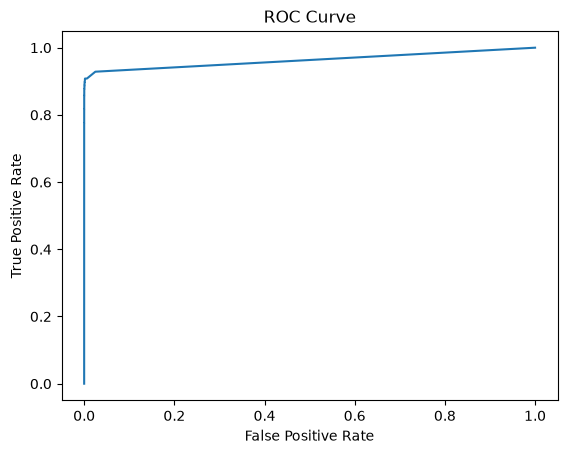

In [29]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, prob)

plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

In [30]:
importance = rf_model.feature_importances_

for feature, value in zip(X_train.columns, importance):
    print(feature, round(value, 4))

Time 0.013
V1 0.0153
V2 0.0148
V3 0.0195
V4 0.0305
V5 0.0099
V6 0.0135
V7 0.0246
V8 0.0126
V9 0.0311
V10 0.0741
V11 0.0453
V12 0.1333
V13 0.0102
V14 0.1364
V15 0.0119
V16 0.0718
V17 0.1703
V18 0.0282
V19 0.0104
V20 0.013
V21 0.0187
V22 0.0123
V23 0.0084
V24 0.0083
V25 0.0079
V26 0.0196
V27 0.013
V28 0.0103
Amount 0.012


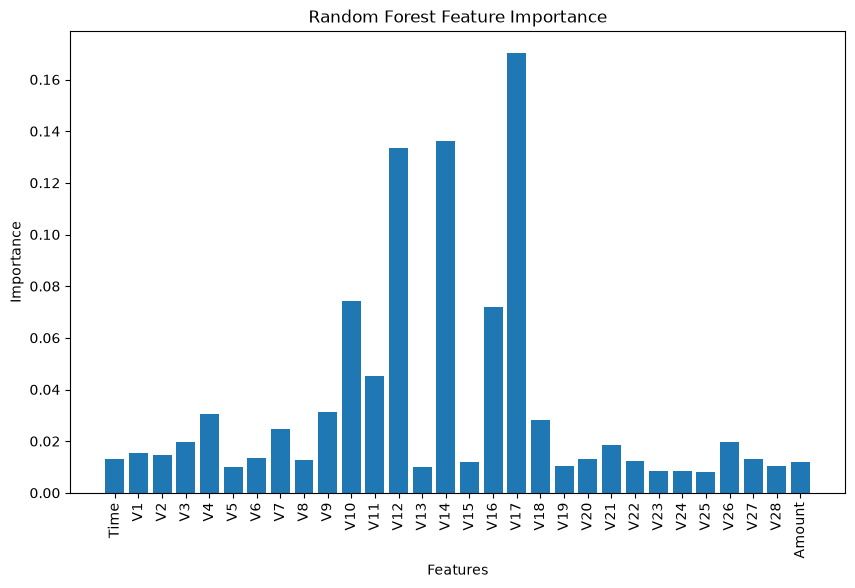

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(X_train.columns, importance)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.xticks(rotation=90)


plt.show()